# GQA Union Amplification vs. Top-p

单独绘制 LLaMA3 / Qwen3 上 Quest + Top-p、DS + Top-p 的四条放大倍率曲线。

**源代码与数据**
- 论文中现有 PDF：`Paper/DAC2027/Figures/motivation_union_amp_vs_topp.pdf`，与 `论文画图/Motivation/` 中的 PDF 相同。
- 原始函数：`论文画图/Motivation/plot_motivation_figures.ipynb` 中的 `plot_union_amp_vs_topp()`。
- 本文件沿用 `Figures/Motivation/plot_motivation_figures.ipynb` 的倍率乘号，使用用户调整后的窄画布及底部单列图例。
- 数据提取自 `Figures/Motivation/TopP_ppl_KVamp.xlsx` 的 `union amp` 列：`llama3` 的 Quest / DS 块位于 N:U / A:H；`qwen3` 的 Quest / DS 块位于 A:H / J:Q。

**运行与修改**

依次运行下面两个代码单元。第二个代码单元开头显式列出 `TOP_P_THRESHOLDS`、`UNION_AMPLIFICATION`、`UNION_STYLES` 和 `PLOT_SETTINGS`，直接修改后重新运行即可。
默认仅绘制 p=0.1–0.9，保留原始数据精度；数据不是从曲线图片中估读的。
倍率是 group union 相对于平均 per-head selected tokens 的无量纲比值，不是实测 HBM 字节流量或 KV-cache 分配容量。

图会在 notebook 内显示，并将 PDF 和 300 dpi PNG 保存到本文件夹；不会覆盖论文目录中的原图。
支持从本文件夹或项目根目录启动，绘图不依赖 Excel 文件。依赖：NumPy、Matplotlib、IPython。


**当前强调区间**

阴影覆盖当前四条曲线的全局最小值至最大值，并以两条灰色虚线标记边界；当前为 2.06×–2.60×。这是观测值范围，不是置信区间。修改数据后边界会自动更新。
图例紧凑程度由 `PLOT_SETTINGS["legend_labelspacing"]` 和 `PLOT_SETTINGS["legend_borderpad"]` 控制；阴影样式由 `shade_*` 参数控制。


In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pad_inches': 0.1}

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np


def setup_style():
    for name in ("Times New Roman.ttf", "Times New Roman Bold.ttf"):
        path = Path("/System/Library/Fonts/Supplemental") / name
        if path.exists():
            font_manager.fontManager.addfont(str(path))
    mpl.rcParams.update({
        "font.family": "Times New Roman",
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "axes.linewidth": 0.8,
        "lines.linewidth": 1.8,
        "lines.markersize": 4.5,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.facecolor": "white",
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.1,
    })


setup_style()


Top-p: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]
LLaMA3: Quest+Top-p: [2.07 2.22 2.33 2.39 2.43 2.48 2.52 2.54 2.53]
LLaMA3: DS+Top-p: [2.06 2.2  2.3  2.35 2.4  2.45 2.49 2.52 2.54]
Qwen3: Quest+Top-p: [2.24 2.29 2.35 2.39 2.42 2.46 2.48 2.5  2.51]
Qwen3: DS+Top-p: [2.3  2.37 2.43 2.47 2.51 2.54 2.57 2.59 2.62]
Saved: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig2-KV-Amplification/motivation_union_amp_vs_topp.pdf
Saved: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig2-KV-Amplification/motivation_union_amp_vs_topp.png


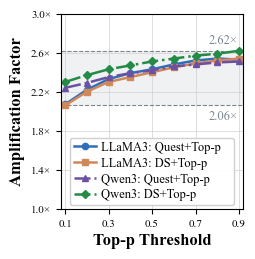

In [39]:
# Editable plotting data: dimensionless union amplification ratios.
# Source: Figures/Motivation/TopP_ppl_KVamp.xlsx, "union amp" columns.
# Each array follows TOP_P_THRESHOLDS; p=0 and p=1 are not plotted.
TOP_P_THRESHOLDS = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
UNION_AMPLIFICATION = {
    "llama3_quest": np.array([2.07, 2.22, 2.33, 2.39, 2.43, 2.48, 2.52, 2.54, 2.53]),
    "llama3_ds":    np.array([2.06, 2.20, 2.30, 2.35, 2.40, 2.45, 2.49, 2.52, 2.54]),
    "qwen3_quest":  np.array([2.24, 2.29, 2.35, 2.39, 2.42, 2.46, 2.48, 2.50, 2.51]),
    "qwen3_ds":     np.array([2.30, 2.37, 2.43, 2.47, 2.51, 2.54, 2.57, 2.59, 2.62]),
}

# Method key, legend label, color, marker, line style.
UNION_STYLES = [
    ("llama3_quest", "LLaMA3: Quest+Top-p", "#2F6FBA", "o", "-"),
    ("llama3_ds",    "LLaMA3: DS+Top-p",    "#d08759", "s", "-"),
    ("qwen3_quest",  "Qwen3: Quest+Top-p",  "#6A51A3", "^", "-."),
    ("qwen3_ds",     "Qwen3: DS+Top-p",     "#238B45", "D", "-."),
]

PLOT_SETTINGS = {
    "figsize": (2.2, 2.5),
    "margins": {"left": 0.16, "right": 0.99, "bottom": 0.20, "top": 0.98},
    "xlim": (0.08, 0.92),
    "ylim": (2.0, 2.9),
    "xticks": [0.1, 0.3, 0.5, 0.7, 0.9],
    "yticks": [1.0, 1.4, 1.8, 2.2, 2.6, 3.0],
    "xlabel": "Top-p Threshold",
    "ylabel": "Amplification Factor",
    "label_fontsize": 12,
    "tick_fontsize": 8,
    "linewidth": 1.8,
    "markersize": 4.5,
    "legend_fontsize": 9,
    "legend_ncol": 1,
    "legend_labelspacing": 0.30,  # Row spacing, in legend-font units.
    "legend_borderpad": 0.30,     # Padding inside the legend frame.
    "shade_color": "#AEB6BE",
    "shade_alpha": 0.18,
    "shade_edge_color": "#7A848E",
    "shade_edge_width": 0.8,
    "shade_edge_style": "--",
    "legend_bbox": (0.05, 0.02, 0.9, 0.0),
    "dpi": 300,
}
OUTPUT_NAME = "motivation_union_amp_vs_topp"


def union_amplification_figure(thresholds, amplification, styles=None, settings=None):
    """Return a standalone figure using the original curve and legend styles."""
    styles = UNION_STYLES if styles is None else styles
    settings = PLOT_SETTINGS if settings is None else settings
    x = np.asarray(thresholds, dtype=float)
    if x.ndim != 1 or not np.all(np.isfinite(x)) or not np.all(np.diff(x) > 0):
        raise ValueError("Thresholds must be a finite, strictly increasing 1D array.")
    visible = (x > 0.0) & (x < 1.0)
    values = {key: np.asarray(amplification[key], dtype=float) for key, *_ in styles}
    for key, y in values.items():
        if y.shape != x.shape or not np.all(np.isfinite(y)):
            raise ValueError(f"{key}: expected {x.shape} finite amplification values.")

    # Fixed margins keep notebook preview and PDF export layouts consistent.
    fig, ax = plt.subplots(figsize=settings["figsize"])
    fig.subplots_adjust(**settings["margins"])
    ax.set_axisbelow(True)
    if not np.any(visible):
        raise ValueError("At least one top-p threshold must lie between 0 and 1.")

    # Global min/max of the displayed curves; this is not a confidence interval.
    plotted_values = np.concatenate([y[visible] for y in values.values()])
    amp_min, amp_max = float(plotted_values.min()), float(plotted_values.max())
    ax.axhspan(
        amp_min, amp_max, color=settings["shade_color"],
        alpha=settings["shade_alpha"], linewidth=0, zorder=0,
    )
    for bound in (amp_min, amp_max):
        ax.axhline(
            bound, color=settings["shade_edge_color"],
            linewidth=settings["shade_edge_width"],
            linestyle=settings["shade_edge_style"], zorder=1,
        )
        ax.annotate(
            f"{bound:.2f}×",
            xy=(0.97, bound),
            xycoords=ax.get_yaxis_transform(),
            xytext=(0, -4 if bound == amp_min else 3),
            textcoords="offset points",
            ha="right",
            va="top" if bound == amp_min else "bottom",
            fontsize=9,
            color=settings["shade_edge_color"],
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85,
                pad=0.3,
            ),
            zorder=5,
        )
    for key, label, color, marker, linestyle in styles:
        ax.plot(
            x[visible], values[key][visible], label=label, color=color,
            marker=marker, linestyle=linestyle,
            linewidth=settings["linewidth"], markersize=settings["markersize"],
        )

    label_font = {
        "size": settings["label_fontsize"],
        "weight": "bold",
        "fontfamily": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    }
    ax.set_xlabel(settings["xlabel"], fontdict=label_font)
    ax.set_ylabel(settings["ylabel"], fontdict=label_font)
    ax.set(
        xlim=settings["xlim"], ylim=settings["ylim"],
        xticks=settings["xticks"], yticks=settings["yticks"],
    )
    ax.tick_params(axis="both", labelsize=settings["tick_fontsize"])
    ax.yaxis.set_major_formatter(
        mpl.ticker.FuncFormatter(lambda value, _: f"{value:.1f}\N{MULTIPLICATION SIGN}")
    )
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.grid(True, color="#d0d0d0", linewidth=0.6, alpha=0.8)
    
    ax.legend(
        loc="lower center", 
        bbox_to_anchor=settings["legend_bbox"],
        mode="expand", borderaxespad=0.0,
        frameon=True, framealpha=0.92,
        fontsize=settings["legend_fontsize"], ncol=settings["legend_ncol"],
        labelspacing=settings["legend_labelspacing"],
        borderpad=settings["legend_borderpad"], handlelength=1.8,
        handletextpad=0.4, columnspacing=0.8,
    )
    return fig


# Print the same editable arrays used for plotting.
print("Top-p:", TOP_P_THRESHOLDS)
for key, label, *_ in UNION_STYLES:
    print(f"{label}: {UNION_AMPLIFICATION[key]}")

if "fig_union_amp" in globals():
    plt.close(fig_union_amp)
fig_union_amp = union_amplification_figure(
    TOP_P_THRESHOLDS, UNION_AMPLIFICATION, styles=UNION_STYLES,
)

# Save beside this notebook, both from its own folder and the project root.
_here = Path.cwd().resolve()
_relative_dir = Path("会用到的论文图与复现/fig2-KV-Amplification")
_candidates = (_here, _here / _relative_dir)
OUTPUT_DIR = next(
    (path for path in _candidates if (path / "plot_union_amp_vs_topp.ipynb").exists()),
    None,
)
if OUTPUT_DIR is None:
    raise FileNotFoundError("Run from the notebook folder or the SparseAttention project root.")

fig_union_amp.savefig(OUTPUT_DIR / f"{OUTPUT_NAME}.pdf", bbox_inches="tight", pad_inches=0.1)
fig_union_amp.savefig(
    OUTPUT_DIR / f"{OUTPUT_NAME}.png", dpi=PLOT_SETTINGS["dpi"],
    bbox_inches="tight", pad_inches=0.1,
)
print("Saved:", OUTPUT_DIR / f"{OUTPUT_NAME}.pdf")
print("Saved:", OUTPUT_DIR / f"{OUTPUT_NAME}.png")
plt.show()
plt.close(fig_union_amp)
